In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("data/daily_requests.csv", parse_dates=["day"])
s = df.set_index("day")["requests"]
print(s.describe())

count     1826.000000
mean      9160.666484
std       1415.972289
min       4492.000000
25%       8269.000000
50%       9157.000000
75%       9941.500000
max      17962.000000
Name: requests, dtype: float64


In [45]:
full_range = pd.date_range(s.index.min(), s.index.max(), freq="D")
print("Пропущенных дней:", len(full_range.difference(s.index)))
print("Дубликатов дат:", s.index.duplicated().sum())
print("Дней с нулём:", (s == 0).sum())

Пропущенных дней: 0
Дубликатов дат: 0
Дней с нулём: 0
1826


In [61]:
print(s.nlargest(5))
print(s.nsmallest(5))

day
2023-09-29    17962
2025-12-15    16388
2024-04-15    15899
2021-09-02    15205
2025-01-07    15023
Name: requests, dtype: int64
day
2021-12-25    4492
2022-11-24    5350
2021-01-01    5482
2021-01-03    5564
2021-12-24    5564
Name: requests, dtype: int64


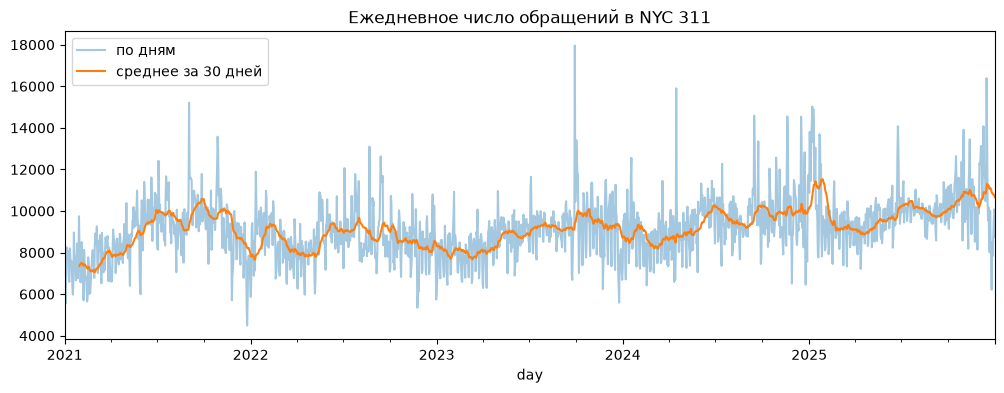

In [38]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.set_title("Ежедневное число обращений в NYC 311")
s.plot(ax=ax, alpha=0.4, label="по дням")
s.rolling(30).mean().plot(ax=ax, label="среднее за 30 дней")
ax.legend()
fig.savefig("files/daily_requests.png", dpi=150, bbox_inches="tight")
plt.show()

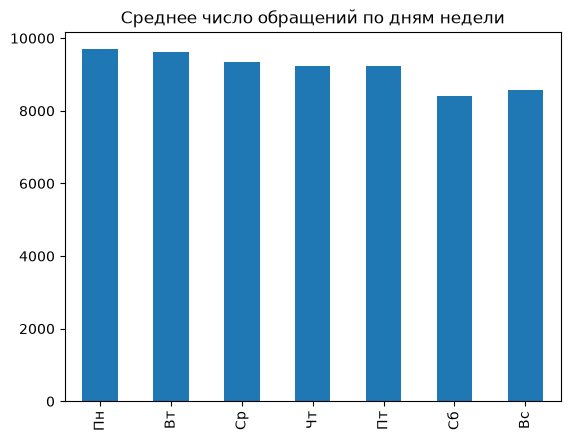

In [40]:
by_week = s.groupby(s.index.dayofweek).mean()
by_week.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_week.plot(kind="bar", title="Среднее число обращений по дням недели")
plt.show()

In [58]:
import numpy as np

x = df["requests"].to_numpy()
n = len(s)
k = int(np.ceil(1 + np.log2(n)))

edges = np.linspace(x.min(), x.max(), k + 1)
counts, edges = np.histogram(x, bins=edges)
rel = counts / n
mids = (edges[:-1] + edges[1:]) / 2

print(f"n={n}, k={k}, edges={np.round(edges,1)}")
print(f"counts={counts}, rel={np.round(rel,3)}")


n=1826, k=12, edges=[ 4492.   5614.5  6737.   7859.5  8982.  10104.5 11227.  12349.5 13472.
 14594.5 15717.  16839.5 17962. ]
counts=[  6  61 216 545 632 247  74  24  15   3   2   1], rel=[0.003 0.033 0.118 0.298 0.346 0.135 0.041 0.013 0.008 0.002 0.001 0.001]


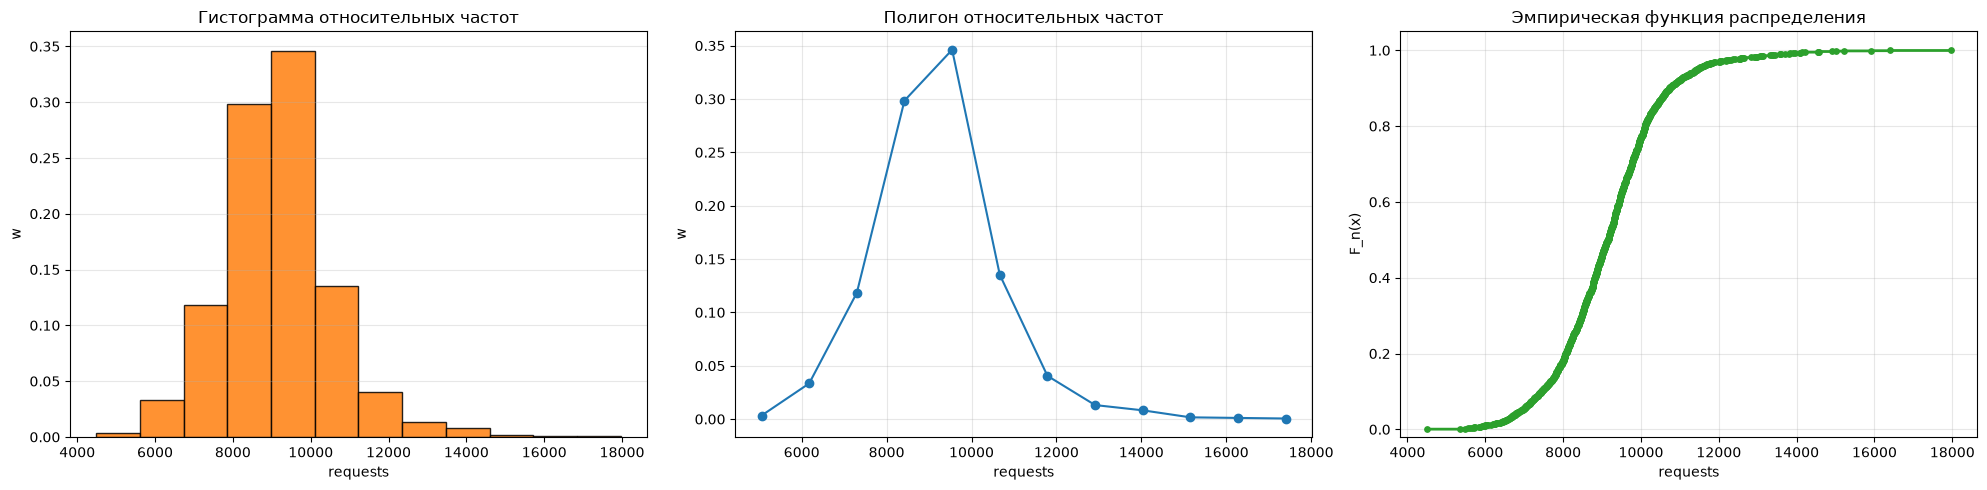

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- 1. Гистограмма относительных частот ---
axes[0].hist(mids, bins=edges, weights=rel,
             edgecolor="black", color="tab:orange", alpha=0.85)
axes[0].set_title("Гистограмма относительных частот")
axes[0].set_xlabel("requests"); axes[0].set_ylabel("w")
axes[0].grid(True, axis="y", alpha=0.3)

# --- 2. Полигон относительных частот ---
axes[1].plot(mids, rel, marker="o", color="tab:blue")
axes[1].set_title("Полигон относительных частот")
axes[1].set_xlabel("requests"); axes[1].set_ylabel("w")
axes[1].grid(True, alpha=0.3)

# --- 3. ЭФР (по исходной выборке!) ---
xs = np.unique(x)
Fs = np.array([(x <= xi).mean() for xi in xs])
axes[2].step(xs, Fs, where="post", color="tab:green", linewidth=2)
axes[2].scatter(xs, Fs, color="tab:green", s=15, zorder=3)
axes[2].set_title("Эмпирическая функция распределения")
axes[2].set_xlabel("requests"); axes[2].set_ylabel("F_n(x)")
axes[2].set_ylim(-0.02, 1.05)
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("files/grafs.png", dpi=150, bbox_inches="tight")
plt.show()